In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

data = pd.read_csv("cifar-10.csv")

# data.head()


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [3]:
x = data.drop('label', axis=1).values
y = data['label'].values

x = x.reshape(-1,32,32,3)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

x_train = x_train/255.0
x_test = x_test/255.0

model = keras.Sequential([        
    layers.Input(shape=(32,32,3)),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')    
])

# layers.Dropout(0.3) # can use this to increase accuracy with more number of epochs

model.summary()

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.2
)

loss, accuracy = model.evaluate(x_test, y_test)
print("Loss : ", loss)
print("Accuracy : ", accuracy)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2304)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         295,040 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 40s 37ms/step - accuracy: 0.4078 - loss: 1.6517 - val_accuracy: 0.4908 - val_loss: 1.4351
Epoch 2/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 37s 37ms/step - accuracy: 0.5233 - loss: 1.3471 - val_accuracy: 0.5304 - val_loss: 1.3358
Epoch 3/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 41s 37ms/step - accuracy: 0.5704 - loss: 1.2192 - val_accuracy: 0.5441 - val_loss: 1.2852
Epoch 4/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 41s 36ms/step - accuracy: 0.6031 - loss: 1.1237 - val_accuracy: 0.5664 - val_loss: 1.2422
Epoch 5/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 37s 37ms/step - accuracy: 0.6308 - loss: 1.0479 - val_accuracy: 0.5809 - val_loss: 1.2264
Epoch 6/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 41s 37ms/step - accuracy: 0.6538 - loss: 0.9833 - val_accuracy: 0.5778 - val_loss: 1.2407
Epoch 7/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 41s 37ms/step - accuracy: 0.6758 - loss: 0.9216 - val_accuracy: 0.5779 - val_loss: 1.2549
Epoch 8/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 41s 38ms/step - accuracy: 0.6927 -

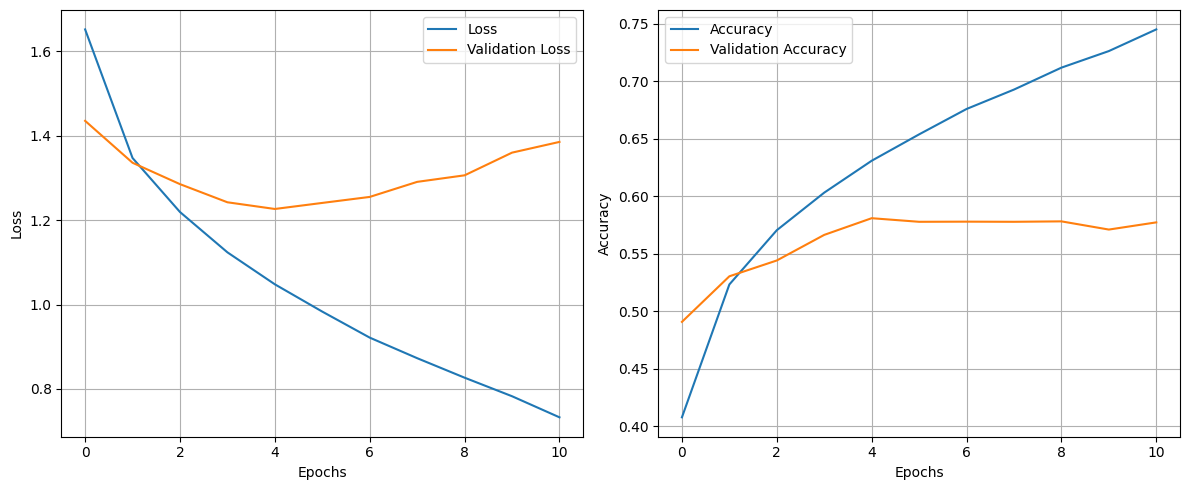

In [6]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label="Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label="Accuracy")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()